# NIDS — CTU-13 Hyperparameter Tuning

Gói đầu vào: NIDS_Kaggle_Training, commit dfb8446. Bật GPU, thêm dataset riêng tư và chạy từ trên xuống. Chỉ sử dụng train/validation trong tuning; chưa chạy full test. Nếu một trial bị gián đoạn, lưu thư mục chưa hoàn thành ra vị trí khác trước khi chạy lại.

In [2]:
import sys
import torch
import numpy as np
import pandas as pd
import sklearn
import pyarrow
import xgboost
import lightgbm

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyArrow:", pyarrow.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)

print("\nCUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())

assert torch.cuda.is_available(), "GPU is not enabled"

for i in range(torch.cuda.device_count()):
    gpu = torch.cuda.get_device_properties(i)
    print(f"\nGPU {i}: {gpu.name}")
    print("VRAM GiB:", round(gpu.total_memory / 1024**3, 2))

print("\nGPU ENVIRONMENT READY")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
NumPy: 2.1.3
Pandas: 2.3.3
Scikit-learn: 1.6.1
PyArrow: 23.0.1
XGBoost: 3.4.1
LightGBM: 4.6.0

CUDA available: True
CUDA version: 13.0
GPU count: 2

GPU 0: Tesla T4
VRAM GiB: 14.56

GPU 1: Tesla T4
VRAM GiB: 14.56

GPU ENVIRONMENT READY


In [3]:
!nvidia-smi

Wed Nov 25 06:28:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
from pathlib import Path
from zipfile import ZipFile
import shutil
import os

INPUT = Path("/kaggle/input")
ROOT = Path("/kaggle/working/NIDS")

ROOT.mkdir(parents=True, exist_ok=True)

manifests = list(INPUT.rglob("kaggle_manifest.json"))

if manifests:

    source = manifests[0].parent

    print("Dataset source:", source)

    shutil.copytree(
        source,
        ROOT,
        dirs_exist_ok=True
    )

else:

    archives = list(
        INPUT.rglob("NIDS_Kaggle_Training.zip")
    )

    assert archives, "Training package not found"

    with ZipFile(archives[0]) as z:
        z.extractall(ROOT)

os.chdir(ROOT)

os.environ["PYTHONPATH"] = str(ROOT / "src")

assert (ROOT / "src/nids/final_cnn.py").exists()
assert (ROOT / "kaggle_manifest.json").exists()

print("Project root:", Path.cwd())

print("\nKAGGLE PROJECT READY")

Dataset source: /kaggle/input/datasets/chienvoo/nids-kaggle-training
Project root: /kaggle/working/NIDS

KAGGLE PROJECT READY


In [5]:
import hashlib
import json

manifest = json.loads(
    (ROOT / "kaggle_manifest.json").read_text(
        encoding="utf-8"
    )
)

print("Git commit:", manifest["git_commit"])

for relative, expected in manifest["sha256"].items():

    path = ROOT / relative

    assert path.exists(), f"Missing file: {relative}"

    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1048576), b""
        ):
            h.update(block)

    assert h.hexdigest() == expected, relative

    print("PASS:", relative)

print("\nKAGGLE DATA INTEGRITY PASSED")

Git commit: dfb84460072a0bcaeed01d9eec0e1ac0dd371531
PASS: data/processed/final/cic/train.parquet
PASS: data/processed/final/cic/validation.parquet
PASS: data/processed/final/cic/test.parquet
PASS: data/processed/final/cic/manifest.json
PASS: data/processed/final/cic/split_indices.npz
PASS: data/processed/final/ctu/train.parquet
PASS: data/processed/final/ctu/validation.parquet
PASS: data/processed/final/ctu/test.parquet
PASS: data/processed/final/ctu/manifest.json
PASS: data/processed/final/ctu/split_indices.npz

KAGGLE DATA INTEGRITY PASSED


In [6]:
subprocess_check = __import__("subprocess")
subprocess_check.run([sys.executable, "-m", "nids.final_cnn", "--help"], cwd=ROOT, check=True)

usage: final_cnn.py [-h] [--dataset {cic,ctu,both}]
                    [--variants {cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} [{cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} ...]]
                    [--smoke] [--epochs EPOCHS] [--batch-size BATCH_SIZE]
                    [--width WIDTH] [--lr LR] [--dropout DROPOUT]
                    [--patience PATIENCE] [--seed SEED]
                    [--device {auto,cpu,cuda}]
                    [--class-weight {auto,none,sqrt,balanced}] [--amp]
                    [--tune-only] [--run-id RUN_ID]

options:
  -h, --help            show this help message and exit
  --dataset {cic,ctu,both}
  --variants {cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} [{cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} ...]
  --smoke
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --width WIDTH
  --lr LR
  --dropout DROPOUT
  --patience PATIENCE
  --seed SEED
  --device {auto,cpu,cuda}
  --class-weight {auto,none,sqrt,balanced}
  --amp
  --tune-only
  --run-id RUN_ID


CompletedProcess(args=['/usr/bin/python3', '-m', 'nids.final_cnn', '--help'], returncode=0)

In [7]:
subprocess_check.run([sys.executable, "-m", "pytest", "-q", "tests/test_final_pipeline.py", "tests/test_final_cnn.py", "tests/test_final_tuning.py"], cwd=ROOT, check=True)

.................                                                        [100%]
=============================== warnings summary ===============================
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
    prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))

../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
  /usr/local/l

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q', 'tests/test_final_pipeline.py', 'tests/test_final_cnn.py', 'tests/test_final_tuning.py'], returncode=0)

In [8]:
import subprocess, sys, os, uuid
GPU_RUN_ID = "GPU_CHECK_" + uuid.uuid4().hex[:8]
subprocess.run([sys.executable, "-u", "-m", "nids.final_cnn", "--dataset", "ctu", "--variants", "cnn_se_mhsa", "--smoke", "--epochs", "1", "--batch-size", "512", "--width", "32", "--lr", "0.001", "--dropout", "0.1", "--class-weight", "sqrt", "--device", "cuda", "--amp", "--tune-only", "--run-id", GPU_RUN_ID], cwd=ROOT, check=True)

Device: cuda


/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_se_mhsa Epoch 1/1 Loss=0.40717 ValF1=0.893031
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa               0.9208              0.896421           0.889666       0.893031           1          6.263991
Saved: /kaggle/working/NIDS/outputs/final/tuning/ctu/GPU_CHECK_99eafb31


CompletedProcess(args=['/usr/bin/python3', '-u', '-m', 'nids.final_cnn', '--dataset', 'ctu', '--variants', 'cnn_se_mhsa', '--smoke', '--epochs', '1', '--batch-size', '512', '--width', '32', '--lr', '0.001', '--dropout', '0.1', '--class-weight', 'sqrt', '--device', 'cuda', '--amp', '--tune-only', '--run-id', 'GPU_CHECK_99eafb31'], returncode=0)

In [9]:
from pathlib import Path
import json
import pandas as pd

folder = (
    ROOT
    / "outputs/final/tuning/ctu" / GPU_RUN_ID
)

result = json.loads(
    (folder / "tuning_metrics.json").read_text()
)

assert result["device"] == "cuda"
assert result["arguments"]["amp"] is True
assert result["arguments"]["tune_only"] is True

assert "test" not in result["split_sizes"]

for name, model in result["models"].items():

    assert "test" not in model

    print("Model:", name)
    print("Best epoch:", model["best_epoch"])
    print("Validation F1:", model["validation"]["f1_score"])

display(
    pd.read_csv(folder / "tuning_metrics.csv")
)

print("\nGPU AMP TUNING CHECK PASSED")

Model: cnn_se_mhsa
Best epoch: 1
Validation F1: 0.893030794165316


,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Best epoch,Training seconds
0,cnn_se_mhsa,0.9208,0.896421,0.889666,0.893031,1,6.263991



GPU AMP TUNING CHECK PASSED


## 9. Thiết kế sáu cấu hình tuning CTU-13

In [10]:
import pandas as pd
TRIALS = [dict(id=i, width=w, lr=lr, dropout=d, class_weight=c) for i,w,lr,d,c in [
    ("T01",32,.001,.1,"none"), ("T02",32,.001,.1,"sqrt"),
    ("T03",32,.001,.1,"balanced"), ("T04",64,.001,.1,"sqrt"),
    ("T05",32,.0005,.1,"sqrt"), ("T06",32,.001,.2,"sqrt")]]
display(pd.DataFrame(TRIALS))

,id,width,lr,dropout,class_weight
0,T01,32,0.0010,0.1,none
1,T02,32,0.0010,0.1,sqrt
2,T03,32,0.0010,0.1,balanced
3,T04,64,0.0010,0.1,sqrt
4,T05,32,0.0005,0.1,sqrt
5,T06,32,0.0010,0.2,sqrt


## 10. Huấn luyện tự động — chỉ train và validation

In [11]:
import subprocess, sys, json, os, math
TUNING_ROOT = ROOT / "outputs/final/tuning/ctu"
TUNING_ROOT.mkdir(parents=True, exist_ok=True)
EXPECTED_SIZES = {"train":57903,"validation":12408}

def validate_trial(trial):
    folder = TUNING_ROOT / trial["id"]
    saved = json.loads((folder / "tuning_metrics.json").read_text())
    a = saved["arguments"]
    expected = {"dataset":"ctu", "variants":["cnn_se_mhsa"], "width":trial["width"], "lr":trial["lr"], "dropout":trial["dropout"], "class_weight":trial["class_weight"], "epochs":15, "batch_size":512, "seed":42, "patience":5, "amp":True, "tune_only":True, "smoke":False, "run_id":trial["id"]}
    assert all(a[k] == v for k,v in expected.items()), f"Config mismatch: {trial['id']}"
    assert saved["split_sizes"] == EXPECTED_SIZES
    assert saved["device"].startswith("cuda")
    source_manifest = json.loads((ROOT / "data/processed/final/ctu/manifest.json").read_text())
    assert saved["split_sha256"] == source_manifest["split_sha256"]
    model = saved["models"]["cnn_se_mhsa"]
    assert "test" not in model and math.isfinite(model["validation"]["f1_score"])
    for name in ["cnn_se_mhsa_history.csv", "cnn_se_mhsa_best_state.pt", "cnn_preprocessing.joblib", "tuning_metrics.csv"]:
        assert (folder / name).is_file(), name
    return model

for trial in TRIALS:
    folder = TUNING_ROOT / trial["id"]
    if (folder / "tuning_metrics.json").exists():
        validate_trial(trial)
        print("Already completed:",trial["id"])
        continue
    if folder.exists():
        raise RuntimeError(f"Incomplete trial: {folder}. Archive it before retrying.")
    command = [sys.executable,"-u","-m","nids.final_cnn","--dataset","ctu","--variants","cnn_se_mhsa","--epochs","15","--batch-size","512","--width",str(trial["width"]),"--lr",str(trial["lr"]),"--dropout",str(trial["dropout"]),"--class-weight",trial["class_weight"],"--patience","5","--seed","42","--device","cuda","--amp","--tune-only","--run-id",trial["id"]]
    print("START TRIAL:",trial["id"],flush=True)
    subprocess.run(command,cwd=ROOT,env={**os.environ,"PYTHONPATH":str(ROOT/"src")},check=True)
    validate_trial(trial)
    print("COMPLETED:",trial["id"],flush=True)
print("ALL CTU TUNING TRIALS COMPLETED")

START TRIAL: T01
Device: cuda


/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_se_mhsa Epoch 1/15 Loss=0.21545 ValF1=0.933977
ctu/cnn_se_mhsa Epoch 2/15 Loss=0.11902 ValF1=0.955353
ctu/cnn_se_mhsa Epoch 3/15 Loss=0.10070 ValF1=0.955926
ctu/cnn_se_mhsa Epoch 4/15 Loss=0.08266 ValF1=0.963314
ctu/cnn_se_mhsa Epoch 5/15 Loss=0.07324 ValF1=0.966581
ctu/cnn_se_mhsa Epoch 6/15 Loss=0.06922 ValF1=0.972545
ctu/cnn_se_mhsa Epoch 7/15 Loss=0.06418 ValF1=0.973019
ctu/cnn_se_mhsa Epoch 8/15 Loss=0.05857 ValF1=0.972956
ctu/cnn_se_mhsa Epoch 9/15 Loss=0.05555 ValF1=0.976146
ctu/cnn_se_mhsa Epoch 10/15 Loss=0.05527 ValF1=0.971065
ctu/cnn_se_mhsa Epoch 11/15 Loss=0.05402 ValF1=0.981699
ctu/cnn_se_mhsa Epoch 12/15 Loss=0.05021 ValF1=0.978839
ctu/cnn_se_mhsa Epoch 13/15 Loss=0.04908 ValF1=0.979268
ctu/cnn_se_mhsa Epoch 14/15 Loss=0.04625 ValF1=0.980499
ctu/cnn_se_mhsa Epoch 15/15 Loss=0.04069 ValF1=0.984545
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa             0.988556              0.98

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_se_mhsa Epoch 1/15 Loss=0.21984 ValF1=0.934360
ctu/cnn_se_mhsa Epoch 2/15 Loss=0.12572 ValF1=0.954854
ctu/cnn_se_mhsa Epoch 3/15 Loss=0.10693 ValF1=0.951528
ctu/cnn_se_mhsa Epoch 4/15 Loss=0.09455 ValF1=0.963807
ctu/cnn_se_mhsa Epoch 5/15 Loss=0.07923 ValF1=0.964289
ctu/cnn_se_mhsa Epoch 6/15 Loss=0.07384 ValF1=0.966323
ctu/cnn_se_mhsa Epoch 7/15 Loss=0.06487 ValF1=0.975958
ctu/cnn_se_mhsa Epoch 8/15 Loss=0.05795 ValF1=0.969903
ctu/cnn_se_mhsa Epoch 9/15 Loss=0.05973 ValF1=0.975854
ctu/cnn_se_mhsa Epoch 10/15 Loss=0.05606 ValF1=0.977673
ctu/cnn_se_mhsa Epoch 11/15 Loss=0.05156 ValF1=0.981450
ctu/cnn_se_mhsa Epoch 12/15 Loss=0.05010 ValF1=0.979889
ctu/cnn_se_mhsa Epoch 13/15 Loss=0.05004 ValF1=0.974600
ctu/cnn_se_mhsa Epoch 14/15 Loss=0.04671 ValF1=0.978454
ctu/cnn_se_mhsa Epoch 15/15 Loss=0.04113 ValF1=0.984130
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa             0.988233              0.98

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


... (3 outputs left out)

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_se_mhsa Epoch 1/15 Loss=0.24806 ValF1=0.929876
ctu/cnn_se_mhsa Epoch 2/15 Loss=0.13069 ValF1=0.949021
ctu/cnn_se_mhsa Epoch 3/15 Loss=0.11118 ValF1=0.953334
ctu/cnn_se_mhsa Epoch 4/15 Loss=0.09695 ValF1=0.937526
ctu/cnn_se_mhsa Epoch 5/15 Loss=0.08600 ValF1=0.958163
ctu/cnn_se_mhsa Epoch 6/15 Loss=0.07975 ValF1=0.964455
ctu/cnn_se_mhsa Epoch 7/15 Loss=0.06969 ValF1=0.970809
ctu/cnn_se_mhsa Epoch 8/15 Loss=0.06185 ValF1=0.968191
ctu/cnn_se_mhsa Epoch 9/15 Loss=0.06243 ValF1=0.975182
ctu/cnn_se_mhsa Epoch 10/15 Loss=0.06005 ValF1=0.975286
ctu/cnn_se_mhsa Epoch 11/15 Loss=0.05533 ValF1=0.977754
ctu/cnn_se_mhsa Epoch 12/15 Loss=0.05556 ValF1=0.978356
ctu/cnn_se_mhsa Epoch 13/15 Loss=0.05520 ValF1=0.976471
ctu/cnn_se_mhsa Epoch 14/15 Loss=0.04991 ValF1=0.979180
ctu/cnn_se_mhsa Epoch 15/15 Loss=0.04973 ValF1=0.978561
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa             0.984365              0.96

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_se_mhsa Epoch 1/15 Loss=0.23442 ValF1=0.934273
ctu/cnn_se_mhsa Epoch 2/15 Loss=0.13576 ValF1=0.947302
ctu/cnn_se_mhsa Epoch 3/15 Loss=0.11672 ValF1=0.953069
ctu/cnn_se_mhsa Epoch 4/15 Loss=0.10686 ValF1=0.952032
ctu/cnn_se_mhsa Epoch 5/15 Loss=0.09792 ValF1=0.899558
ctu/cnn_se_mhsa Epoch 6/15 Loss=0.09492 ValF1=0.959203
ctu/cnn_se_mhsa Epoch 7/15 Loss=0.07998 ValF1=0.970028
ctu/cnn_se_mhsa Epoch 8/15 Loss=0.07307 ValF1=0.958987
ctu/cnn_se_mhsa Epoch 9/15 Loss=0.07016 ValF1=0.972891
ctu/cnn_se_mhsa Epoch 10/15 Loss=0.06569 ValF1=0.967953
ctu/cnn_se_mhsa Epoch 11/15 Loss=0.06156 ValF1=0.967217
ctu/cnn_se_mhsa Epoch 12/15 Loss=0.06091 ValF1=0.974916
ctu/cnn_se_mhsa Epoch 13/15 Loss=0.06020 ValF1=0.972024
ctu/cnn_se_mhsa Epoch 14/15 Loss=0.05616 ValF1=0.971005
ctu/cnn_se_mhsa Epoch 15/15 Loss=0.05713 ValF1=0.975880
      Model  Validation Accuracy  Validation Precision  Validation Recall  Validation F1  Best epoch  Training seconds
cnn_se_mhsa             0.982108              0.97

## 11. Tổng hợp kết quả và chọn cấu hình theo Validation Binary F1

In [12]:
rows=[]
for trial in TRIALS:
    model=validate_trial(trial)
    m=model["validation"]
    rows.append({"Trial":trial["id"],"Width":trial["width"],"Learning Rate":trial["lr"],"Dropout":trial["dropout"],"Class Weight":trial["class_weight"],"Accuracy":m["accuracy"],"Precision":m["precision"],"Recall":m["recall"],"F1-score":m["f1_score"],"Best Epoch":model["best_epoch"],"Training Seconds":model["training_seconds"]})
summary=pd.DataFrame(rows).sort_values(["F1-score","Trial"],ascending=[False,True]).reset_index(drop=True)
summary.to_csv(TUNING_ROOT/"tuning_summary.csv",index=False)
best=summary.iloc[0].to_dict()
(TUNING_ROOT/"best_config.json").write_text(json.dumps(best,indent=2),encoding="utf-8")
display(summary)
print("BEST CONFIGURATION:",best)

,Trial,Width,Learning Rate,Dropout,Class Weight,Accuracy,Precision,Recall,F1-score,Best Epoch,Training Seconds
0,T01,32,0.0010,0.1,none,0.988556,0.988418,0.980703,0.984545,15,30.046889
1,T02,32,0.0010,0.1,sqrt,0.988233,0.986704,0.981570,0.984130,15,30.580192
2,T04,64,0.0010,0.1,sqrt,0.988153,0.984799,0.983304,0.984051,14,44.144483
3,T05,32,0.0005,0.1,sqrt,0.984365,0.969401,0.989159,0.979180,14,30.627090
4,T03,32,0.0010,0.1,balanced,0.982834,0.962955,0.991977,0.977251,15,30.665900
5,T06,32,0.0010,0.2,sqrt,0.982108,0.978005,0.973764,0.975880,15,30.760801


BEST CONFIGURATION: {'Trial': 'T01', 'Width': 32, 'Learning Rate': 0.001, 'Dropout': 0.1, 'Class Weight': 'none', 'Accuracy': 0.9885557704706641, 'Precision': 0.9884178321678322, 'Recall': 0.980702515177797, 'F1-score': 0.9845450587723117, 'Best Epoch': 15, 'Training Seconds': 30.046888705999947}


## 12. Biểu đồ so sánh sáu trial

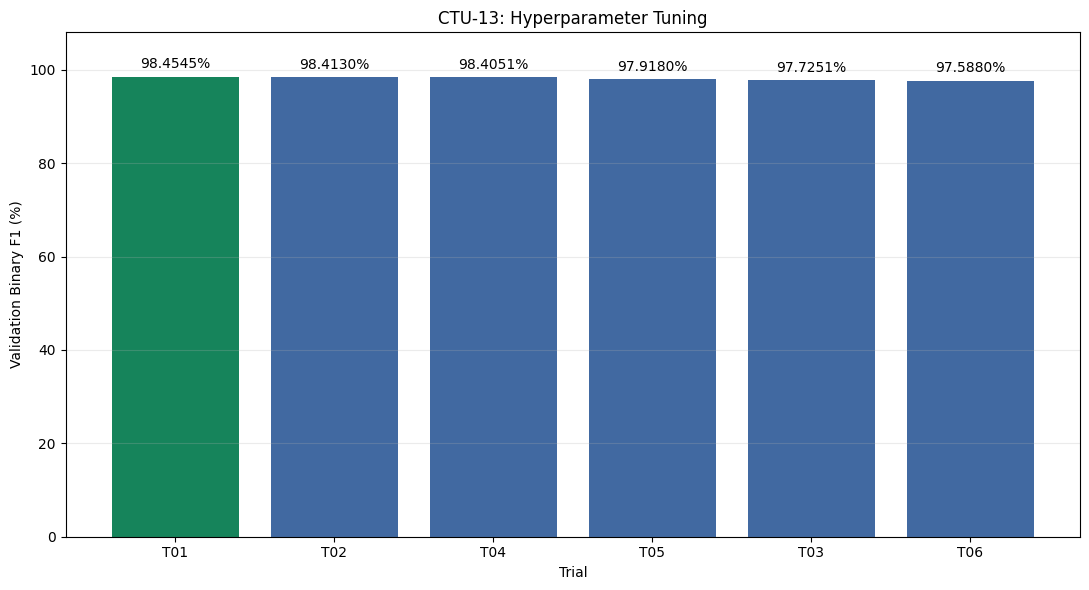

In [13]:
import matplotlib.pyplot as plt
FIGURES=ROOT/"reports/final/figures/tuning/ctu"
FIGURES.mkdir(parents=True,exist_ok=True)
fig,ax=plt.subplots(figsize=(11,6))
bars=ax.bar(summary["Trial"],summary["F1-score"]*100,color=["#16845b" if i==0 else "#4169a1" for i in range(len(summary))])
ax.bar_label(bars,fmt="%.4f%%",padding=4)
ax.set(ylim=(0,108),title="CTU-13: Hyperparameter Tuning",xlabel="Trial",ylabel="Validation Binary F1 (%)")
ax.grid(axis="y",alpha=.25)
fig.tight_layout()
fig.savefig(FIGURES/"01_hyperparameter_tuning_f1.png",dpi=300,bbox_inches="tight")
plt.show()

## 13. Learning curves

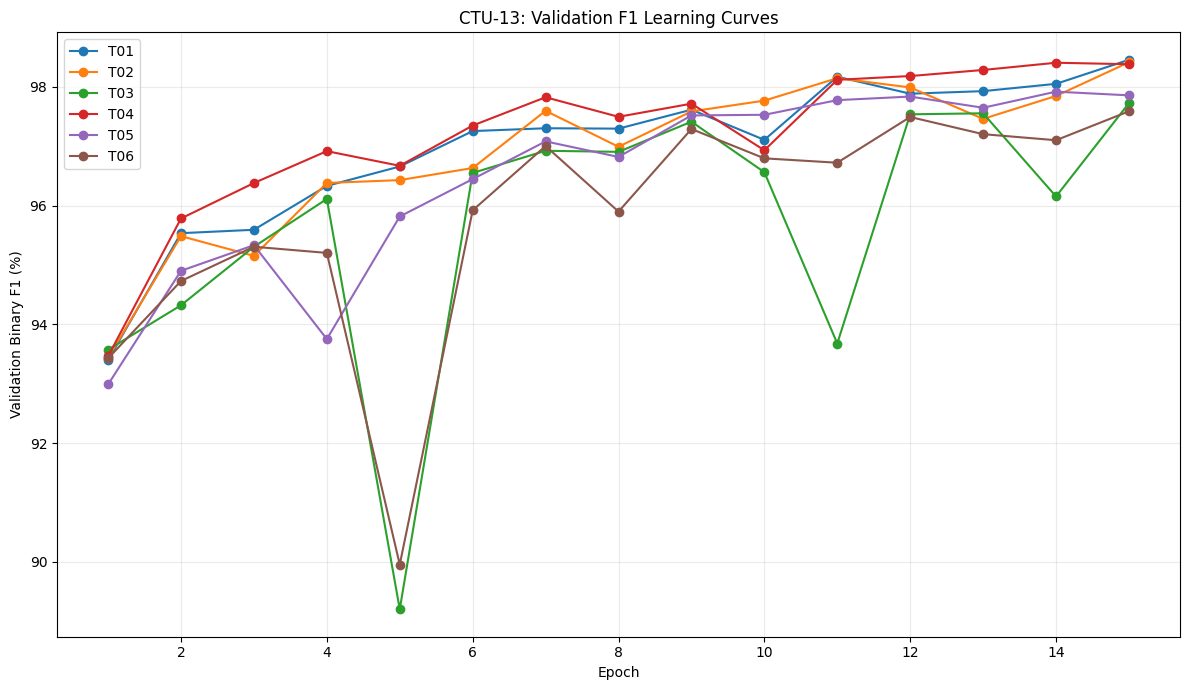

In [14]:
fig,ax=plt.subplots(figsize=(12,7))
for trial in TRIALS:
    h=pd.read_csv(TUNING_ROOT/trial["id"]/"cnn_se_mhsa_history.csv")
    ax.plot(h["epoch"],h["validation_f1"]*100,marker="o",label=trial["id"])
ax.set(title="CTU-13: Validation F1 Learning Curves",xlabel="Epoch",ylabel="Validation Binary F1 (%)")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(FIGURES/"02_tuning_learning_curves.png",dpi=300,bbox_inches="tight")
plt.show()

## 14. Xuất báo cáo Markdown tiếng Việt

In [15]:
REPORTS=ROOT/"reports/final"
lines=["# Hyperparameter Tuning — CTU-13","","## 1. Mục tiêu","","Lựa chọn siêu tham số cho CNN + SE + MHSA theo Validation Binary F1 (lớp 1).","","## 2. Phương pháp","","- Train: 57.903 mẫu; validation: 12.408 mẫu.","- Không đọc tập test trong tuning.","- GPU: "+torch.cuda.get_device_name(0),"- AMP FP16; seed 42; batch size 512; tối đa 15 epoch; patience 5.","- Commit dữ liệu/mã nguồn: "+manifest["git_commit"],"","## 3. Kết quả","","| Trial | Width | LR | Dropout | Weight | Accuracy | Precision | Recall | Validation F1 | Best epoch |","|---|---:|---:|---:|---|---:|---:|---:|---:|---:|"]
for _,r in summary.iterrows():
    lines.append(f'| {r["Trial"]} | {r["Width"]} | {r["Learning Rate"]} | {r["Dropout"]} | {r["Class Weight"]} | {r["Accuracy"]*100:.4f}% | {r["Precision"]*100:.4f}% | {r["Recall"]*100:.4f}% | {r["F1-score"]*100:.4f}% | {r["Best Epoch"]} |')
lines += ["","## 4. Biểu đồ","","![Tuning F1](figures/tuning/ctu/01_hyperparameter_tuning_f1.png)","","![Learning curves](figures/tuning/ctu/02_tuning_learning_curves.png)","","## 5. Cấu hình được chọn","",f'- Trial: {best["Trial"]}',f'- Width: {best["Width"]}',f'- LR: {best["Learning Rate"]}',f'- Dropout: {best["Dropout"]}',f'- Class weight: {best["Class Weight"]}',f'- Validation F1: {best["F1-score"]*100:.4f}%',"","## 6. Giới hạn","","Sáu cấu hình với một seed trên tập chia nội bộ ngẫu nhiên; không phải đánh giá độc lập theo thời gian hoặc kịch bản. Nhãn CTU là nhãn của bộ CSV đang sử dụng. Chưa đánh giá test chính thức và chưa chứng minh vượt baseline."]
path=REPORTS/"07_HYPERPARAMETER_TUNING_CTU.md"
path.write_text("\n".join(lines)+"\n",encoding="utf-8")
print("REPORT CREATED:",path)

REPORT CREATED: /kaggle/working/NIDS/reports/final/07_HYPERPARAMETER_TUNING_CTU.md


## 15. Đóng gói kết quả — tải hai ZIP về trước khi kết thúc phiên

In [16]:
from zipfile import ZipFile, ZIP_DEFLATED
archives=[]
for name,base in [("NIDS_CTU13_Tuning_Results",TUNING_ROOT),("NIDS_CTU13_Tuning_Reports",REPORTS)]:
    dest=Path("/kaggle/working")/(name+".zip")
    with ZipFile(dest,"w",ZIP_DEFLATED) as z:
        for p in sorted(base.rglob("*")):
            if p.is_file(): z.write(p,p.relative_to(ROOT).as_posix())
    with ZipFile(dest) as z: assert z.testzip() is None
    archives.append(dest)
    print(dest)
print("ALL CTU TUNING ARTIFACTS COMPLETED")

/kaggle/working/NIDS_CTU13_Tuning_Results.zip
/kaggle/working/NIDS_CTU13_Tuning_Reports.zip
ALL CTU TUNING ARTIFACTS COMPLETED
